# Deck synergy, rounds 3–7: training, stacking, and synergy from cards seen together

`deck_synergy_v2.ipynb` ended with the nonland FM + deck features + the pick model's affinity column as the best
game-level deck model (−1.20 ×1000 test log loss vs linear), and 0.262 draft-level Spearman against 0.271 for the
draft-trained LightGBM deck model. This notebook covers the five rounds after it, on the same 12 sets:

| round | script | question |
|---|---|---|
| 3 | `deck_synergy_v3.py`, `deck_synergy_v3_blend.py` | more from affinity (profile, per-card fit)? does the game model add to LightGBM? |
| 4 | `deck_synergy_v4.py`, `deck_synergy_v4_draft.py` | round 2's pair variants, properly trained; LightGBM with deck features, boosted from the game model |
| 5 | `deck_synergy_v5.py` | learn pairs from the cards each game actually *saw*, not the decklist |
| 6 | `deck_synergy_v6.py` | is that seen-together synergy real? held-out test and an unseen-card placebo |
| 7 | `deck_synergy_v7.py` | final pair tables and per-card synergy hubs |

Every game-level number is test-game log loss, paired against a reference model on the same games, ×1000 (lower is
better), with the 95% interval of the paired difference. Draft-level numbers are Spearman of the calibrated deck
score against the test drafts' W/(W+L).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(40); pl.Config.set_fmt_str_lengths(60); pl.Config.set_tbl_width_chars(220)


def load(round_dir, name="results.json"):
    return {p.parts[-3].split(".")[0]: json.loads(p.read_text())
            for p in sorted((ROOT / "results").glob(f"*.PremierDraft/{round_dir}/{name}"))}


def by_model(res):
    return {s: {m["model"]: m for m in r["models"]} for s, r in res.items()}


def dots(ax, series, key, err, ref_label):
    """Per-set dots with 95% intervals, one colour per series in fixed order."""
    cols = [BLUE, ORANGE, AQUA, YELLOW, VIOLET, MAGENTA]
    for j, (label, per_set) in enumerate(series.items()):
        x = np.arange(len(SETS)) + (j - (len(series) - 1) / 2) * 0.16
        ax.errorbar(x, [per_set[s][key] * 1000 for s in SETS], yerr=[per_set[s][err] * 1000 for s in SETS],
                    fmt="o", ms=4.5, color=cols[j], label=label, elinewidth=1)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_xticks(np.arange(len(SETS)), SETS)
    ax.set_ylabel(f"test log loss vs {ref_label} (×1000)")
    ax.legend(fontsize=8, loc="lower left")


V3, V4, V5, V6, V7 = (by_model(load(f"deck_synergy_v{i}")) for i in (3, 4, 5, 6, 7))
SETS = sorted(V3)
print(f"{len(SETS)} sets: {', '.join(SETS)}")

12 sets: BLB, DFT, DSK, EOE, FDN, FIN, LCI, MKM, MSH, OTJ, SOS, TDM


## 1. Round 3: the earlier models were under-trained

Round 3 tried two ways to get more out of the pick model's affinity than one mean-affinity column:

* **affinity profile:** the fit distribution, not just its mean: the worst-fitting card, the spread of fit, the
  count of off-plan cards (below the training 10th percentile of fit)
* **card fit:** each card gets its own weight on how well it fits the rest of the deck (a build-around vs a card
  that is good anywhere), warm-started from the nested model

Card fit first looked like a 12/12 win. The control explains why: the *same* warm-started continuation with card fit
held at zero did just as well. Round 2's models stopped at their first validation plateau at learning rate 3e-3.
`synergy._train` now takes `lr_drops` (on a plateau, return to the best state and divide the rate by 3), and every
model from here on trains with two drops. The chart below is the final run with the fix: against the properly trained
FM + affinity, card fit and the continuation control are both close to zero.

model,mean vs linear ×1000,mean draft Spearman
str,f64,f64
"""linear""",0.0,0.233
"""linear + deck features""",-0.741,0.252
"""linear + deck features + aff""",-1.215,0.265
"""fm4 nonland + deck features""",-1.24,0.263
"""fm4 nonland + deck features + aff""",-1.396,0.268
"""linear + deck features + affinity profile""",-1.224,0.264
"""linear + deck features + aff + card fit""",-1.404,0.266
"""fm4 nonland + deck features + aff + card fit""",-1.464,0.267
"""fm4 nonland + deck features + aff, continued (control)""",-1.428,0.266


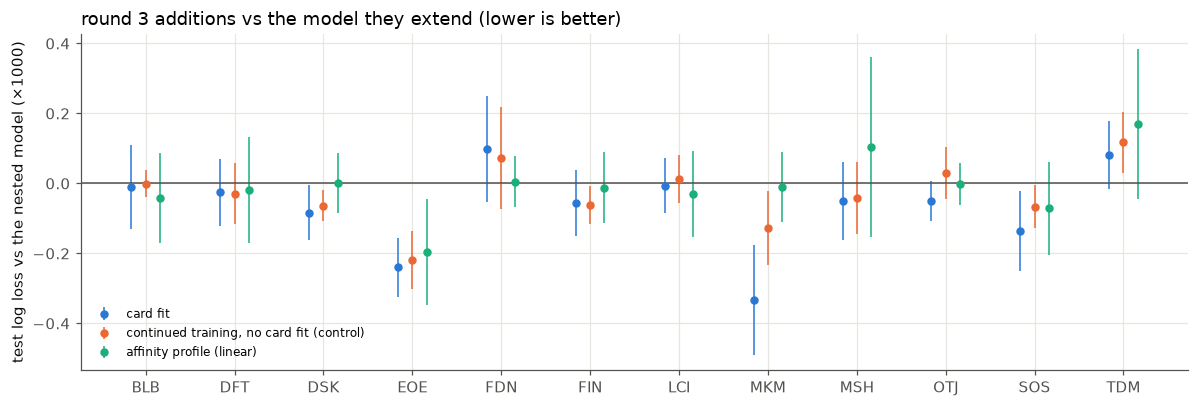

In [2]:
ref = "fm4 nonland + deck features + aff"
series = {"card fit": {s: V3[s][ref + " + card fit"] for s in SETS},
          "continued training, no card fit (control)": {s: V3[s][ref + ", continued (control)"] for s in SETS},
          "affinity profile (linear)": {s: {k: V3[s]["linear + deck features + affinity profile"][k]
                                             - V3[s]["linear + deck features + aff"][k] * (k == "vs v2 best")
                                             for k in ("vs v2 best", "vs v2 best ±95%")} for s in SETS}}
series["affinity profile (linear)"] = {s: {"vs v2 best": V3[s]["linear + deck features + affinity profile"]["vs v2 best"]
                                                         - V3[s]["linear + deck features + aff"]["vs v2 best"],
                                           "vs v2 best ±95%": V3[s]["linear + deck features + affinity profile"]["vs v2 best ±95%"]}
                                       for s in SETS}
fig, ax = plt.subplots(figsize=(11, 3.8))
dots(ax, series, "vs v2 best", "vs v2 best ±95%", "the nested model")
ax.set_title("round 3 additions vs the model they extend (lower is better)", loc="left")
plt.tight_layout()

t = pl.DataFrame([{"model": m, "mean vs linear ×1000": np.mean([V3[s][m]["vs linear"] for s in SETS]) * 1000,
                   "mean draft Spearman": np.mean([V3[s][m]["draft spearman"] for s in SETS])}
                  for m in V3["MSH"]])
t.with_columns(pl.exclude("model").round(3))

The "affinity profile" dots are the profile model minus the single-column model; the profile's interval is against
the FM, so it is only a rough guide. **The mean carries all the affinity signal:** fitted together, the mean gets
+0.13 log-odds per sd on 12/12 sets, while the worst card, spread and off-plan count average +0.01 to +0.03.

In [3]:
w = pl.DataFrame([{"set": s, **V3[s]["linear + deck features + affinity profile"]["affinity weights (log-odds per sd)"]}
                  for s in SETS])
w.with_columns(pl.exclude("set").round(3))

set,aff mean,aff worst card,aff sd,aff off-plan cards
str,f64,f64,f64,f64
"""BLB""",0.138,0.011,0.035,-0.003
"""DFT""",0.132,0.02,0.038,-0.007
"""DSK""",0.129,0.014,0.029,-0.005
"""EOE""",0.064,0.021,0.035,-0.022
"""FDN""",0.11,0.013,0.017,-0.005
"""FIN""",0.154,0.002,0.014,-0.014
"""LCI""",0.131,0.017,0.028,-0.013
"""MKM""",0.118,0.023,0.044,-0.007
"""MSH""",0.104,0.022,0.025,-0.003


## 2. Round 4: pair terms are saturated; LightGBM + the game model is the best deck model

With the training fix, every pair-term variant beats `linear + deck features + aff` by about the same amount:
FM rank 4 / 8 / 16 between nonland cards, rank 4 over all cards, and pairs built as a learned map of the pick model's
card vectors.

pair terms,mean ×1000,sets better,sets significant,draft Spearman
str,f64,i64,i64,f64
"""fm4 nonland""",-0.181,12,9,0.268
"""fm8 nonland""",-0.175,12,8,0.266
"""fm16 nonland""",-0.166,11,7,0.267
"""fm4 all cards""",-0.141,10,7,0.267
"""affinity pairs (k=8)""",-0.171,11,5,0.268
"""affinity pairs (k=8) + fm4 nonland""",-0.163,10,5,0.269


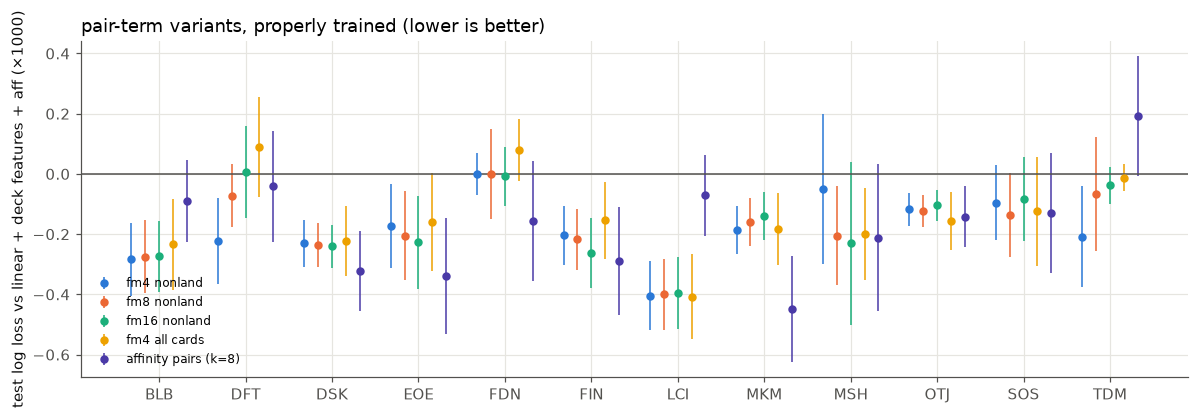

In [4]:
pairs = ["fm4 nonland", "fm8 nonland", "fm16 nonland", "fm4 all cards", "affinity pairs (k=8)"]
fig, ax = plt.subplots(figsize=(11, 3.8))
dots(ax, {p: {s: V4[s][p] for s in SETS} for p in pairs}, "vs ref", "vs ref ±95%", "linear + deck features + aff")
ax.set_title("pair-term variants, properly trained (lower is better)", loc="left")
plt.tight_layout()
pl.DataFrame([{"pair terms": p, "mean ×1000": np.mean([V4[s][p]["vs ref"] for s in SETS]) * 1000,
               "sets better": sum(V4[s][p]["vs ref"] < 0 for s in SETS),
               "sets significant": sum(V4[s][p]["vs ref"] + V4[s][p]["vs ref ±95%"] < 0 for s in SETS),
               "draft Spearman": np.mean([V4[s][p]["draft spearman"] for s in SETS])}
              for p in pairs + ["affinity pairs (k=8) + fm4 nonland"]]).with_columns(pl.col("mean ×1000", "draft Spearman").round(3))

**Draft level.** LightGBM on registered-deck counts + structure + rank (`improve_deck.py`) is the draft-trained
model. The game-level FM is skill-adjusted: it is fit on games with the skill bucket and ranks as covariates. Round 4
scores the game model *cross-fitted*: each training draft is scored by a model fit on the other half of the training
drafts. LightGBM can then start from the game model's logit (init_score) without learning to trust an in-sample
score.

In [5]:
D4 = load("deck_synergy_v4", "draft.json")
show = {"lgbm": "LightGBM", "game model (fm4 nonland, cross-fitted)": "game FM (skill-adjusted)",
        "lgbm + deck feat + aff": "LightGBM + deck features + aff",
        "lgbm + game model, averaged": "LightGBM + game FM, averaged",
        "lgbm + deck feat + aff + game model, averaged": "LightGBM + DF + aff, averaged with game FM",
        "lgbm, boosted from game model (fm4 nonland)": "LightGBM boosted from game FM"}
dr = pl.DataFrame([{"set": s, **{v: D4[s][k]["spearman"] for k, v in show.items()}} for s in SETS])
display(dr.with_columns(pl.exclude("set").round(3)))
dr.select(pl.exclude("set").mean().round(4))

set,LightGBM,game FM (skill-adjusted),LightGBM + deck features + aff,"LightGBM + game FM, averaged","LightGBM + DF + aff, averaged with game FM",LightGBM boosted from game FM
str,f64,f64,f64,f64,f64,f64
"""BLB""",0.276,0.272,0.275,0.283,0.28,0.282
"""DFT""",0.26,0.254,0.268,0.265,0.269,0.263
"""DSK""",0.279,0.276,0.281,0.286,0.285,0.286
"""EOE""",0.244,0.245,0.246,0.251,0.25,0.252
"""FDN""",0.283,0.277,0.284,0.288,0.286,0.288
"""FIN""",0.283,0.279,0.29,0.289,0.291,0.29
"""LCI""",0.294,0.292,0.297,0.3,0.3,0.302
"""MKM""",0.26,0.255,0.261,0.266,0.264,0.266
"""MSH""",0.279,0.273,0.283,0.288,0.289,0.287


LightGBM,game FM (skill-adjusted),LightGBM + deck features + aff,"LightGBM + game FM, averaged","LightGBM + DF + aff, averaged with game FM",LightGBM boosted from game FM
f64,f64,f64,f64,f64,f64
0.2712,0.2681,0.2754,0.2779,0.2785,0.2784


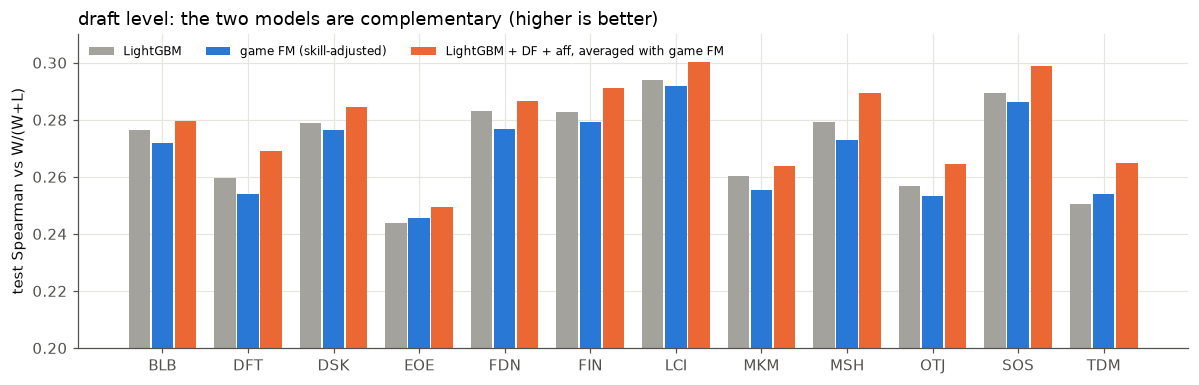

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.6))
cols = {"LightGBM": GRAY, "game FM (skill-adjusted)": BLUE, "LightGBM + DF + aff, averaged with game FM": ORANGE}
x = np.arange(len(SETS))
for j, (k, c) in enumerate(cols.items()):
    ax.bar(x + (j - 1) * 0.27, dr[k], 0.25, color=c, label=k)
ax.set_xticks(x, SETS); ax.set_ylim(0.2, 0.31)
ax.set_ylabel("test Spearman vs W/(W+L)")
ax.set_title("draft level: the two models are complementary (higher is better)", loc="left")
ax.legend(fontsize=8, ncol=3, loc="upper left")
plt.tight_layout()

Neither LightGBM nor the game model beats the other alone (0.271 vs 0.268), but their logit average is better than
LightGBM on all 12 sets (0.278). LightGBM finds build effects from draft records; the game model contributes card
values and synergy that are adjusted for skill. Giving LightGBM the deck features and affinity helps it too (0.275),
since trees on raw counts can't work out castability or pairwise fit. Boosting is no better than averaging.

## 3. Round 5: synergy from cards seen together

A deck-level FM only knows that two cards shared a deck; in most games at most one of them shows up. The **seen FM**
puts its pair terms on the nonland cards each game actually saw (opening hand or drawn), with deck power, seen-card
power, game length, and the number of lands and spells seen (one-hot, so the pair term can't just count spells
drawn: flood / screw). It uses in-game information, so it doesn't predict the deck; it estimates pair values.

**Replication:** both FMs refit on two independent halves of the training drafts, pair values correlated over nonland
pairs in ≥ 2,000 training decks. On OTJ and EOE round 5's penalty grid collapsed the seen FM to no pairs (fixed in
round 6).

set,pairs,deck pair r,seen pair r,seen vs deck pairs r (full fits),seen vs affinity r
str,i64,f64,f64,f64,f64
"""BLB""",12614,0.235,0.571,0.245,0.065
"""DFT""",12703,0.127,0.689,0.254,0.152
"""DSK""",14083,0.153,0.644,0.285,0.186
"""EOE""",9589,0.053,0.038,-0.008,0.001
"""FDN""",11157,0.142,0.709,0.111,0.03
"""FIN""",11469,0.093,0.675,0.282,0.099
"""LCI""",11352,0.14,0.692,0.267,0.001
"""MKM""",12712,0.142,0.758,0.31,0.081
"""MSH""",6251,0.011,0.441,0.168,0.143


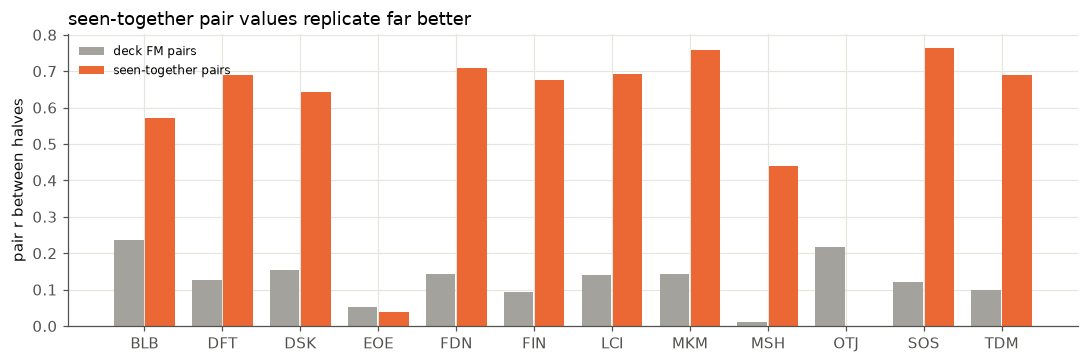

In [7]:
R5 = load("deck_synergy_v5")
rep = pl.DataFrame([{"set": s, **R5[s]["replication"]} for s in SETS])
fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(len(SETS))
ax.bar(x - 0.2, rep["deck pair r"], 0.38, color=GRAY, label="deck FM pairs")
ax.bar(x + 0.2, rep["seen pair r"].fill_nan(0), 0.38, color=ORANGE, label="seen-together pairs")
ax.set_xticks(x, SETS); ax.set_ylabel("pair r between halves")
ax.set_title("seen-together pair values replicate far better", loc="left"); ax.legend(fontsize=8)
plt.tight_layout()
rep.select("set", "pairs", "deck pair r", "seen pair r", "seen vs deck pairs r (full fits)", "seen vs affinity r") \
   .with_columns(pl.exclude("set", "pairs").round(3))

**Does it help deck strength?** The seen pair matrix Q becomes one deck-level column (the deck's mean pairwise Q), and
the deck-only models are scored as before. It barely helps: a pair only matters in the ~10% of games where both cards
show up, and its deck-level average is already mostly in the FM and the affinity column.

In [8]:
pl.DataFrame([{"model": m, "mean vs linear + DF + aff ×1000": np.mean([V5[s][m]["vs ref"] for s in SETS]) * 1000,
               "sets better": sum(V5[s][m]["vs ref"] < 0 for s in SETS),
               "sets significant": sum(V5[s][m]["vs ref"] + V5[s][m]["vs ref ±95%"] < 0 for s in SETS),
               "draft Spearman": np.mean([V5[s][m]["draft spearman"] for s in SETS])}
              for m in V5["MSH"]]).with_columns(pl.col("mean vs linear + DF + aff ×1000", "draft Spearman").round(3))

model,mean vs linear + DF + aff ×1000,sets better,sets significant,draft Spearman
str,f64,i64,i64,f64
"""linear + deck features + aff""",0.0,0,0,0.265
"""fm4 nonland + deck features + aff""",-0.181,12,9,0.268
"""linear + deck features + aff + seen Q""",-0.026,10,2,0.266
"""fm4 nonland + deck features + aff + seen Q""",-0.173,11,8,0.268


## 4. Round 6: is seen-together synergy real?

Repeatability alone could come from deck composition. Two checks:

* **held out:** the seen FM with pairs vs the same model without, on test games
* **placebo:** the identical model with pairs between nonland cards that were in the deck but *not* seen that game.
  Cards that stayed in the library can't interact on the battlefield, so real synergy predicts no gain there. A
  deck-composition artefact would show up in both.

pairs between,mean ×1000,sets significant,mean split-half r
str,f64,i64,f64
"""seen, pairs k=4""",-2.421,12,0.473
"""seen, pairs k=8""",-2.372,12,NaN
"""placebo (unseen), pairs k=4""",-0.076,6,0.063


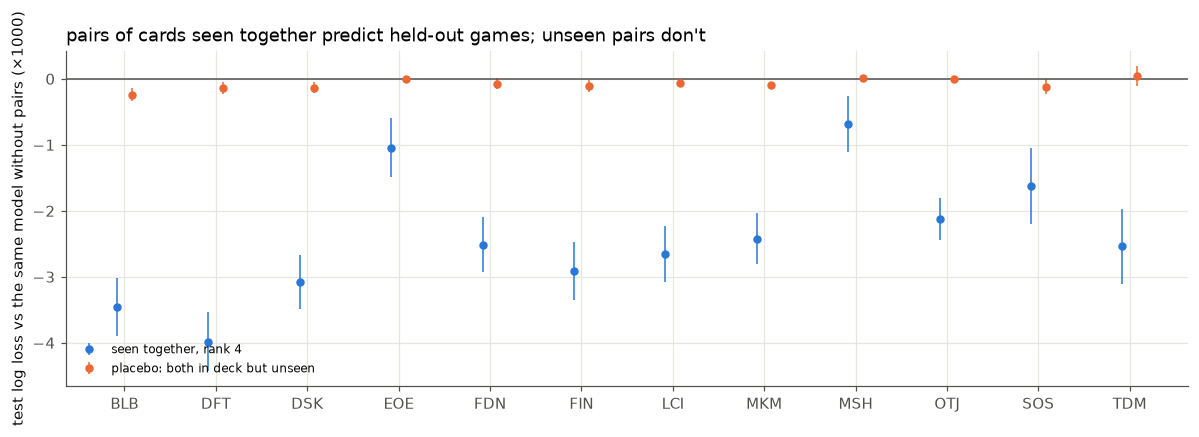

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.8))
dots(ax, {"seen together, rank 4": {s: V6[s]["seen, pairs k=4"] for s in SETS},
          "placebo: both in deck but unseen": {s: V6[s]["placebo (unseen), pairs k=4"] for s in SETS}},
     "vs no pairs", "vs no pairs ±95%", "the same model without pairs")
ax.set_title("pairs of cards seen together predict held-out games; unseen pairs don't", loc="left")
plt.tight_layout()
pl.DataFrame([{"pairs between": m, "mean ×1000": np.mean([V6[s][m]["vs no pairs"] for s in SETS]) * 1000,
               "sets significant": sum(V6[s][m]["vs no pairs"] + V6[s][m]["vs no pairs ±95%"] < 0 for s in SETS),
               "mean split-half r": np.mean([V6[s][m].get("split-half pair r", np.nan) for s in SETS])}
              for m in ("seen, pairs k=4", "seen, pairs k=8", "placebo (unseen), pairs k=4")]) \
  .with_columns(pl.col("mean ×1000", "mean split-half r").round(3))

Seen-together pairs improve held-out prediction on all 12 sets, by −2.4 ×1000 on average. That is about 13× the
deck-level FM's pair gain (−0.18) and more than the deck features and affinity add together (−1.22). The placebo
gains about 30× less and doesn't replicate (r ≈ 0.05). The synergy is about cards meeting in the same game, not about
what decks they are in. Rank 8 ties rank 4.

## 5. Round 7: synergy hubs and pairs

Round 7 refits the seen FM with the penalty grid extended down to 3e-5; round 6's grid had bottomed out on 11 of 12
sets. The held-out gain is unchanged (−2.43 ×1000) and the grid now brackets the optimum. From the final fits:

* `seen_pairs.csv`: Q<sub>ij</sub>, the extra log-odds when both cards are seen, beyond each card's own seen value
* `card_hubs.csv`: each card's own seen value u and its **synergy dependence**, the co-occurrence-weighted mean Q
  over its partners

A synergy hub is a card whose value depends on what it is drawn with. `card_hubs.csv`'s *synergy dependence*
(mean Q over partners) has a catch: a card's own value u and its average pair effect trade off against each other
(r = −0.55 to −0.69 across cards), so a weak card can look synergy-dependent partly by construction. The
**partner spread**, the co-occurrence-weighted sd of Q across a card's partners, can't be faked that way (r with u:
−0.23 to −0.37). It asks whether the card is much better with some partners than with others. Below, cards with at
least 20 partners; the labelled ones are each set's top 4 by spread, with their best partner.

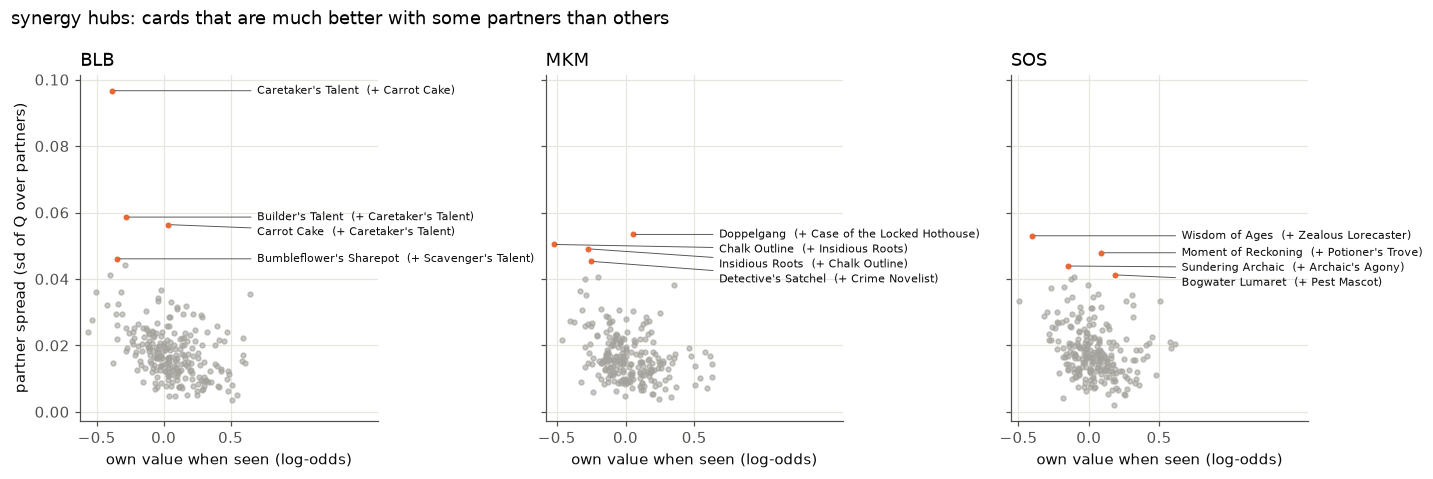

In [10]:
def hubs(s, min_partners=20):
    base = ROOT / "results" / f"{s}.PremierDraft" / "deck_synergy_v7"
    p = pl.read_csv(base / "seen_pairs.csv")
    both = pl.concat([p.select(pl.col("card a").alias("card"), "seen Q", "train decks"),
                      p.select(pl.col("card b").alias("card"), "seen Q", "train decks")])
    w = pl.col("train decks")
    mean = (pl.col("seen Q") * w).sum() / w.sum()
    spread = both.group_by("card").agg(
        (((pl.col("seen Q") - mean) ** 2 * w).sum() / w.sum()).sqrt().alias("partner spread"),
        pl.len().alias("partners"))
    return pl.read_csv(base / "card_hubs.csv").join(spread, on="card").filter(pl.col("partners") >= min_partners)


def repel(ys, gap):
    """Label y positions, top-down, at least `gap` apart."""
    out = []
    for y in ys:
        out.append(min(y, out[-1] - gap) if out else y)
    return out


fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, s in zip(axes, ["BLB", "MKM", "SOS"]):
    h = hubs(s)
    ax.scatter(h["seen value u"], h["partner spread"], s=10, color=GRAY, alpha=0.6)
    top = h.sort("partner spread", descending=True).head(4)
    ax.scatter(top["seen value u"], top["partner spread"], s=24, color=ORANGE, edgecolor=SURFACE, linewidth=1)
    x_lab = h["seen value u"].max() + 0.05
    for r, y in zip(top.iter_rows(named=True), repel(top["partner spread"].to_list(), 0.0045)):
        ax.annotate(f"{r['card']}  (+ {r['best partner']})", (r["seen value u"], r["partner spread"]),
                    xytext=(x_lab, y), fontsize=7.5, color=INK, va="center",
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
    ax.set_title(s, loc="left"); ax.set_xlabel("own value when seen (log-odds)")
    ax.set_xlim(right=x_lab + 0.9)
    ax.set_xticks([-0.5, 0, 0.5])
axes[0].set_ylabel("partner spread (sd of Q over partners)")
fig.suptitle("synergy hubs: cards that are much better with some partners than others", x=0.01, ha="left")
plt.tight_layout()

In [11]:
pl.concat([hubs(s).sort("partner spread", descending=True).head(4).with_columns(pl.lit(s).alias("set")) for s in SETS]) \
  .select("set", "card", "seen value u", "partner spread", "synergy dependence", "best partner", "best Q", "partners") \
  .with_columns(pl.col("seen value u", "partner spread", "synergy dependence", "best Q").round(3))

set,card,seen value u,partner spread,synergy dependence,best partner,best Q,partners
str,str,f64,f64,f64,str,f64,u32
"""BLB""","""Caretaker's Talent""",-0.387,0.097,0.063,"""Carrot Cake""",0.358,57
"""BLB""","""Builder's Talent""",-0.282,0.059,0.06,"""Caretaker's Talent""",0.252,56
"""BLB""","""Carrot Cake""",0.035,0.056,0.024,"""Caretaker's Talent""",0.358,175
"""BLB""","""Bumbleflower's Sharepot""",-0.352,0.046,0.053,"""Scavenger's Talent""",0.2,113
"""DFT""","""Salvation Engine""",0.11,0.056,0.025,"""Pactdoll Terror""",0.141,21
"""DFT""","""Broodheart Engine""",-0.269,0.051,0.051,"""Aatchik, Emerald Radian""",0.185,91
"""DFT""","""Aatchik, Emerald Radian""",-0.138,0.048,0.048,"""Broodheart Engine""",0.185,69
"""DFT""","""Aether Syphon""",-0.495,0.045,0.062,"""Riverchurn Monument""",0.18,125
"""DSK""","""Final Vengeance""",-0.022,0.047,0.037,"""Disturbing Mirth""",0.2,190


The strongest pairs per set (both cards in ≥ 2,000 training decks), with the pick model's affinity alongside. The
two mostly disagree (r ≈ 0.07): drafters group cards by archetype, while these pairs are about cards that are
better when drawn together.

In [12]:
def top_pairs(s, n=5):
    p = pl.read_csv(ROOT / "results" / f"{s}.PremierDraft" / "deck_synergy_v7" / "seen_pairs.csv")
    return p.head(n).with_columns(pl.lit(s).alias("set"))


pl.concat([top_pairs(s) for s in SETS]).select("set", "card a", "card b", "seen Q", "pick affinity", "train decks") \
  .with_columns(pl.col("seen Q", "pick affinity").round(3))

set,card a,card b,seen Q,pick affinity,train decks
str,str,str,f64,f64,f64
"""BLB""","""Caretaker's Talent""","""Carrot Cake""",0.358,9.239,14267.0
"""BLB""","""Builder's Talent""","""Caretaker's Talent""",0.252,6.858,3357.0
"""BLB""","""Heaped Harvest""","""Scavenger's Talent""",0.204,4.466,5338.0
"""BLB""","""Bumbleflower's Sharepot""","""Scavenger's Talent""",0.2,3.213,2725.0
"""BLB""","""Builder's Talent""","""Bumbleflower's Sharepot""",0.192,5.128,5701.0
"""DFT""","""Aatchik, Emerald Radian""","""Broodheart Engine""",0.185,17.523,10140.0
"""DFT""","""Aether Syphon""","""Riverchurn Monument""",0.18,7.674,7464.0
"""DFT""","""Aether Syphon""","""Demonic Junker""",0.166,2.313,2730.0
"""DFT""","""Aether Syphon""","""Cursecloth Wrappings""",0.163,1.465,2045.0


## 6. Takeaways

1. **Train properly before comparing.** Round 2's models stopped at their first plateau. With learning-rate drops,
   the nonland FM + affinity goes from −1.20 to −1.40 ×1000 vs linear (linear retrained the same way), and the
   ranking of models doesn't change. A continued-training control is what showed that card fit's apparent gain
   was just extra training.
2. **Deck-level synergy is saturated.** Every pair-term variant gains about −0.15 to −0.18 ×1000 over the affinity
   column. Rank, lands in the pairs, and pick-model-derived pairs make no difference; neither do affinity profiles
   or per-card fit.
3. **The best deck-strength model is a blend.** LightGBM (with deck features + affinity) averaged with the
   skill-adjusted game FM: 0.279 mean Spearman, against 0.271 for LightGBM and 0.244 for the linear deck model.
   Each model gets something the other misses, and further stacking moves it by 0.001 or less.
4. **Synergy is much larger in the game than in the decklist.** Pairs of cards seen together improve held-out
   games by −2.4 ×1000 on every set and replicate between halves at r ≈ 0.5; an unseen-card placebo gets about
   30× less and doesn't replicate. The hubs, cards much better with some partners than others, are mostly payoffs
   that are weak alone: BLB's Talents and Food, MKM's Chalk Outline with Insidious Roots, DSK's Emerge from the
   Cocoon, SOS's Wisdom of Ages. A card's own value and its average pair effect trade off in this model, so hubs
   are ranked by the spread of their pair values, not their mean.
5. **Why that doesn't improve deck strength:** a deck only collects a pair's effect in the ~10% of games where both
   cards show up, and the deck-level average is already in the FM and affinity. Deck-strength prediction is now
   limited by Bo1 noise, not by its synergy estimates.
6. **Next:** use the seen-together pair values where synergy drives a decision, as a synergy term in the pick bots
   and table simulator; with replay data for more sets, look at pairs that were actually cast together and at
   your-card × opponent-card matchups.